# Neurophysiological Analysis & Metrics Guide
This interactive notebook covers the mathematical theory, executable functions, and synthetic validation examples (high vs. low score exemplars) for all single-cell and population metrics used in our pipeline.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, rotate
from scipy import stats, signal

print("Environment loaded successfully.")

Environment loaded successfully.


## 1. Placeness Score (Spatial Information Z-Score)
### Theory
Quantifies how robustly a neuron fires at specific spatial bins along a linear track. Based on Shannon's Mutual Information adapted for spatial coding (Skaggs et al., 1993):
$$\text{SI} = \sum_i P_i \frac{\lambda_i}{\bar{\lambda}} \log_2 \left(\frac{\lambda_i}{\bar{\lambda}}\right)$$
Statistical significance is assessed via spatial/temporal shuffles to compute a Z-score:
$$Z_{\text{SI}} = \frac{\text{SI}_{\text{actual}} - \mu_{\text{shuf}}}{\sigma_{\text{shuf}}}$$

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, signal
from scipy.ndimage import gaussian_filter1d, rotate

def compute_placeness_score(pos: np.ndarray, trace: np.ndarray, n_bins: int = 50, n_shuffles: int = 30) -> tuple[float, np.ndarray]:
    """Computes the Spatial Information Z-score (placeness score) for a given trace and position vector."""
    p_min, p_max = float(np.nanmin(pos)), float(np.nanmax(pos))
    if p_max <= p_min or not np.isfinite(p_min) or not np.isfinite(p_max):
        return 0.0, np.zeros(n_bins)
        
    bin_edges = np.linspace(p_min, p_max, n_bins + 1)
    bin_idx = np.clip(np.digitize(pos, bin_edges[1:-1]), 0, n_bins - 1)
    
    occupancy = np.bincount(bin_idx, minlength=n_bins).astype(float)
    activity = np.bincount(bin_idx, weights=trace, minlength=n_bins).astype(float)
    tuning = np.zeros(n_bins, dtype=float)
    valid = occupancy > 0
    tuning[valid] = activity[valid] / occupancy[valid]
    tuning = gaussian_filter1d(tuning, sigma=1.5, mode="nearest")
    
    prob_occ = occupancy / np.sum(occupancy) if np.sum(occupancy) > 0 else np.ones(n_bins) / n_bins
    
    def calc_si(t_curve):
        mean_rate = np.sum(prob_occ * t_curve)
        if mean_rate <= 1e-12:
            return 0.0
        ratio = t_curve / mean_rate
        ratio[ratio <= 0] = 1e-12
        return float(np.sum(prob_occ * ratio * np.log2(ratio)))

    actual_si = calc_si(tuning)
    if actual_si <= 0 or np.nanstd(trace) < 1e-6:
        return 0.0, tuning
        
    shuf_si = []
    n_pts = len(trace)
    rng = np.random.default_rng(42)
    for _ in range(n_shuffles):
        shift = rng.integers(int(0.05 * n_pts), int(0.95 * n_pts))
        shuf_trace = np.roll(trace, shift)
        # Helper tuning curve for shuffles
        p_mi, p_ma = float(np.nanmin(pos)), float(np.nanmax(pos))
        b_ed = np.linspace(p_mi, p_ma, n_bins + 1)
        b_id = np.clip(np.digitize(pos, b_ed[1:-1]), 0, n_bins - 1)
        occ_s = np.bincount(b_id, minlength=n_bins).astype(float)
        act_s = np.bincount(b_id, weights=shuf_trace, minlength=n_bins).astype(float)
        tune_s = np.zeros(n_bins, dtype=float)
        val_s = occ_s > 0
        tune_s[val_s] = act_s[val_s] / occ_s[val_s]
        tune_s = gaussian_filter1d(tune_s, sigma=1.5, mode="nearest")
        shuf_si.append(calc_si(tune_s))
        
    mu_shuf = float(np.nanmean(shuf_si))
    sd_shuf = float(np.nanstd(shuf_si))
    placeness_score = float((actual_si - mu_shuf) / sd_shuf) if sd_shuf > 1e-6 else float(actual_si)
    return max(0.0, placeness_score), tuning

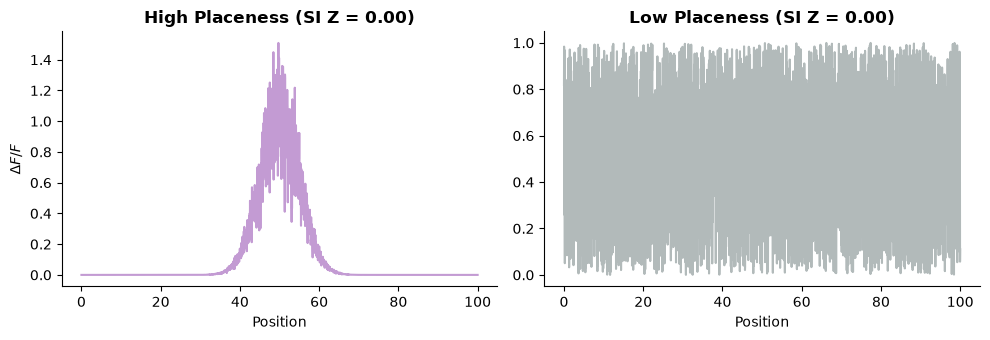

In [7]:
def generate_placeness_exemplars():
    np.random.seed(42)
    n_pts = 3000
    pos = np.linspace(0, 100, n_pts)
    trace_high = np.clip(np.exp(-((pos - 50.0)**2) / 50.0) * (1.0 + 0.2 * np.random.randn(n_pts)), 0, None)
    trace_low = np.random.rand(n_pts)
    
    score_high, tune_high = compute_placeness_score(pos, trace_high)
    score_low, tune_low = compute_placeness_score(pos, trace_low)
    return {"pos": pos, "trace_high": trace_high, "score_high": score_high, "tune_high": tune_high,
            "trace_low": trace_low, "score_low": score_low, "tune_low": tune_low}

p_ex = generate_placeness_exemplars()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=100)
axes[0].plot(p_ex["pos"], p_ex["trace_high"], color='#9b59b6', alpha=0.6)
axes[0].set_title(f"High Placeness (SI Z = {p_ex['score_high']:.2f})", fontweight="bold")
axes[0].set_xlabel("Position")
axes[0].set_ylabel(r"$\Delta F/F$")

axes[1].plot(p_ex["pos"], p_ex["trace_low"], color='#7f8c8d', alpha=0.6)
axes[1].set_title(f"Low Placeness (SI Z = {p_ex['score_low']:.2f})", fontweight="bold")
axes[1].set_xlabel("Position")

for ax in axes:
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 

## 2. Entorhinal Gridness Score (Grid Cells)
### Theory
Grid cells in the medial entorhinal cortex (MEC) exhibit periodic hexagonal firing fields across 2D open environments (Hafting et al., 2005). The **Gridness Score** evaluates the 6-fold rotational symmetry of the 2D spatial autocorrelation map by comparing correlation coefficients at 60° and 120° against 30°, 90°, and 150° rotations:
$$\text{Gridness} = \min(\text{Corr}_{60^\circ, 120^\circ}) - \max(\text{Corr}_{30^\circ, 90^\circ, 150^\circ})$$

In [9]:
def compute_gridness_score(rate_map: np.ndarray) -> float:
    """Computes the 6-fold rotational symmetry gridness score from a 2D spatial rate map."""
    mean_centered = rate_map - np.nanmean(rate_map)
    mean_centered = np.nan_to_num(mean_centered)
    acorr = signal.correlate2d(mean_centered, mean_centered, mode='full')
    acorr /= (np.max(np.abs(acorr)) + 1e-12)
    
    h, w = acorr.shape
    y, x = np.ogrid[:h, :w]
    center_y, center_x = h // 2, w // 2
    r = np.sqrt((x - center_x)**2 + (y - center_y)**2)
    mask = (r >= 5) & (r <= min(h, w) // 2)
    
    corrs = []
    for angle in [30, 60, 90, 120, 150]:
        rotated = rotate(acorr, angle, reshape=False, mode='constant', cval=0.0)
        v1 = acorr[mask]
        v2 = rotated[mask]
        valid = np.isfinite(v1) & np.isfinite(v2)
        if np.sum(valid) > 10:
            r_val, _ = stats.pearsonr(v1[valid], v2[valid])
            corrs.append((angle, r_val if np.isfinite(r_val) else 0.0))
        else:
            corrs.append((angle, 0.0))
            
    corr_dict = dict(corrs)
    min_hex = min(corr_dict.get(60, 0), corr_dict.get(120, 0))
    max_non_hex = max(corr_dict.get(30, 0), corr_dict.get(90, 0), corr_dict.get(150, 0))
    return float(min_hex - max_non_hex)

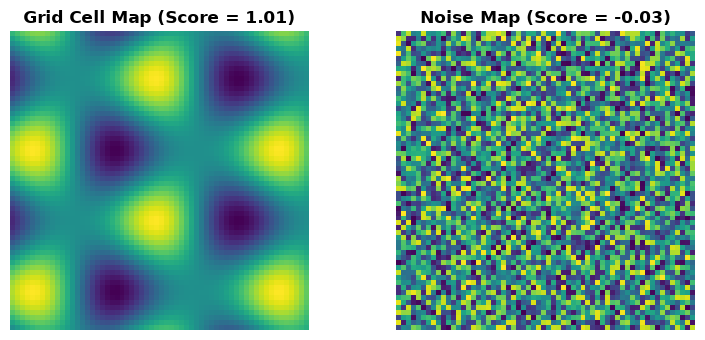

In [11]:
def generate_gridness_exemplars():
    x_g, y_g = np.meshgrid(np.linspace(0, 15, 60), np.linspace(0, 15, 60))
    grid_map = np.sin(x_g) + np.sin(0.5 * x_g + 0.866 * y_g) + np.sin(-0.5 * x_g + 0.866 * y_g)
    noise_map = np.random.rand(60, 60)
    score_grid = compute_gridness_score(grid_map)
    score_noise = compute_gridness_score(noise_map)
    return {"grid_map": grid_map, "score_grid": score_grid, "noise_map": noise_map, "score_noise": score_noise}

g_ex = generate_gridness_exemplars()
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=100)
axes[0].imshow(g_ex["grid_map"], cmap='viridis', origin='lower')
axes[0].set_title(f"Grid Cell Map (Score = {g_ex['score_grid']:.2f})", fontweight="bold")
axes[1].imshow(g_ex["noise_map"], cmap='viridis', origin='lower')
axes[1].set_title(f"Noise Map (Score = {g_ex['score_noise']:.2f})", fontweight="bold")
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Directionality Score ($1 - r_{\text{LR}}$)
### Theory
Measures whether a neuron fires differently during outward vs. inward traversals on a linear track. We compute the Pearson correlation coefficient ($r_{\text{LR}}$) between the leftward and rightward spatial tuning curves, defining the directionality score as:
$$\text{Directionality Score} = 1.0 - r_{\text{LR}}$$
A score near $0$ indicates identical directional firing profiles, whereas a score approaching $2.0$ indicates complete directional divergence or anticorrelation.

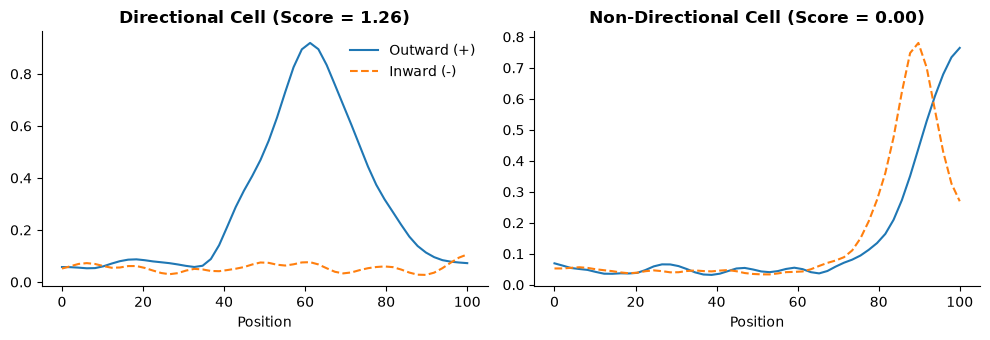

In [25]:
def compute_directionality_score(pos: np.ndarray, mov_dir: np.ndarray, trace: np.ndarray, n_bins: int = 50) -> float:
    """
    Computes directionality score as 1.0 - Pearson r between positive and negative movement tuning curves.
    """
    mask_pos = (mov_dir > 0) & np.isfinite(pos) & np.isfinite(trace)
    mask_neg = (mov_dir < 0) & np.isfinite(pos) & np.isfinite(trace)
    
    p_mi, p_ma = float(np.nanmin(pos)), float(np.nanmax(pos))
    b_ed = np.linspace(p_mi, p_ma, n_bins + 1)
    
    def get_tune(p, tr):
        if len(p) < 10: return np.zeros(n_bins)
        b_id = np.clip(np.digitize(p, b_ed[1:-1]), 0, n_bins - 1)
        occ = np.bincount(b_id, minlength=n_bins).astype(float)
        act = np.bincount(b_id, weights=tr, minlength=n_bins).astype(float)
        tune = np.zeros(n_bins, dtype=float)
        val = occ > 0
        tune[val] = act[val] / occ[val]
        return gaussian_filter1d(tune, sigma=1.5, mode="nearest")

    tune_pos = get_tune(pos[mask_pos], trace[mask_pos])
    tune_neg = get_tune(pos[mask_neg], trace[mask_neg])
    
    if np.std(tune_pos) < 1e-12 or np.std(tune_neg) < 1e-12:
        return 0.0
    r_val, _ = stats.pearsonr(tune_pos, tune_neg)
    if not np.isfinite(r_val):
        return 0.0
    return float(1.0 - r_val)

# Simulation & Plotting Example
def run_directionality_simulation():
    np.random.seed(42)
    n = 2000
    pos = np.tile(np.linspace(0, 100, 200), 10)
    mov_dir = np.random.choice([-1, 1], size=n)
    
    # Directional Cell (different firing patterns for left vs right)
    trace_dir = np.where(mov_dir > 0, np.exp(-((pos - 30)**2)/50), np.exp(-((pos - 70)**2)/50)) + 0.1*np.random.rand(n)
    # Non-Directional Cell (symmetric firing)
    trace_nondir = np.exp(-((pos - 50)**2)/50) + 0.1*np.random.rand(n)
    
    s_dir = compute_directionality_score(pos, mov_dir, trace_dir)
    s_nondir = compute_directionality_score(pos, mov_dir, trace_nondir)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=100)
    axes[0].set_title(f"Directional Cell (Score = {s_dir:.2f})", fontweight="bold")
    axes[0].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_dir[mov_dir>0][:50], 1.5), label="Outward (+)")
    axes[0].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_dir[mov_dir<0][:50], 1.5), label="Inward (-)", linestyle="--")
    axes[0].legend(frameon=False)
    
    axes[1].set_title(f"Non-Directional Cell (Score = {s_nondir:.2f})", fontweight="bold")
    axes[1].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_nondir[mov_dir>0][:50], 1.5), label="Outward (+)")
    axes[1].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_nondir[mov_dir<0][:50], 1.5), label="Inward (-)", linestyle="--")
    
    for ax in axes:
        ax.set_xlabel("Position")
        ax.grid(False)
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

run_directionality_simulation()

In [27]:
def compute_directionality_score(pos: np.ndarray, mov_dir: np.ndarray, trace: np.ndarray, n_bins: int = 50) -> float:
    """
    Computes directionality score as 1.0 - Pearson r between positive and negative movement tuning curves.
    """
    mask_pos = (mov_dir > 0) & np.isfinite(pos) & np.isfinite(trace)
    mask_neg = (mov_dir < 0) & np.isfinite(pos) & np.isfinite(trace)
    
    p_mi, p_ma = float(np.nanmin(pos)), float(np.nanmax(pos))
    b_ed = np.linspace(p_mi, p_ma, n_bins + 1)
    
    def get_tune(p, tr):
        if len(p) < 10: return np.zeros(n_bins)
        b_id = np.clip(np.digitize(p, b_ed[1:-1]), 0, n_bins - 1)
        occ = np.bincount(b_id, minlength=n_bins).astype(float)
        act = np.bincount(b_id, weights=tr, minlength=n_bins).astype(float)
        tune = np.zeros(n_bins, dtype=float)
        val = occ > 0
        tune[val] = act[val] / occ[val]
        return gaussian_filter1d(tune, sigma=1.5, mode="nearest")

    tune_pos = get_tune(pos[mask_pos], trace[mask_pos])
    tune_neg = get_tune(pos[mask_neg], trace[mask_neg])
    
    if np.std(tune_pos) < 1e-12 or np.std(tune_neg) < 1e-12:
        return 0.0
    r_val, _ = stats.pearsonr(tune_pos, tune_neg)
    if not np.isfinite(r_val):
        return 0.0
    return float(1.0 - r_val)

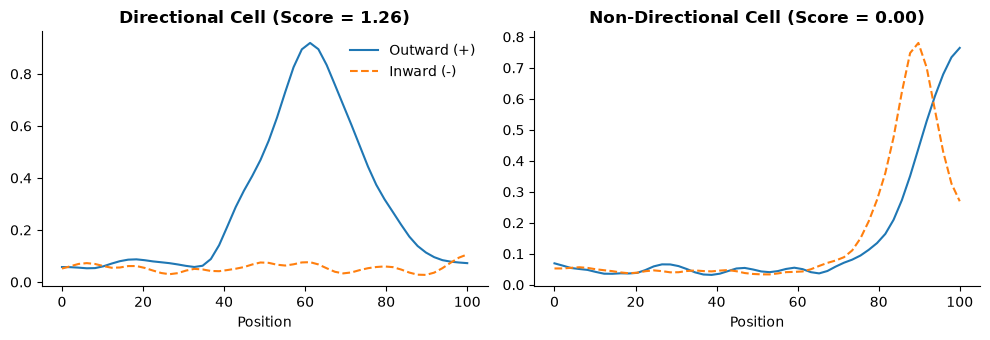

In [28]:
# Simulation & Plotting Example
def run_directionality_simulation():
    np.random.seed(42)
    n = 2000
    pos = np.tile(np.linspace(0, 100, 200), 10)
    mov_dir = np.random.choice([-1, 1], size=n)
    
    # Directional Cell (different firing patterns for left vs right)
    trace_dir = np.where(mov_dir > 0, np.exp(-((pos - 30)**2)/50), np.exp(-((pos - 70)**2)/50)) + 0.1*np.random.rand(n)
    # Non-Directional Cell (symmetric firing)
    trace_nondir = np.exp(-((pos - 50)**2)/50) + 0.1*np.random.rand(n)
    
    s_dir = compute_directionality_score(pos, mov_dir, trace_dir)
    s_nondir = compute_directionality_score(pos, mov_dir, trace_nondir)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=100)
    axes[0].set_title(f"Directional Cell (Score = {s_dir:.2f})", fontweight="bold")
    axes[0].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_dir[mov_dir>0][:50], 1.5), label="Outward (+)")
    axes[0].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_dir[mov_dir<0][:50], 1.5), label="Inward (-)", linestyle="--")
    axes[0].legend(frameon=False)
    
    axes[1].set_title(f"Non-Directional Cell (Score = {s_nondir:.2f})", fontweight="bold")
    axes[1].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_nondir[mov_dir>0][:50], 1.5), label="Outward (+)")
    axes[1].plot(np.linspace(0, 100, 50), gaussian_filter1d(trace_nondir[mov_dir<0][:50], 1.5), label="Inward (-)", linestyle="--")
    
    for ax in axes:
        ax.set_xlabel("Position")
        ax.grid(False)
        ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()

run_directionality_simulation()

## 4. Temporal Drift Score
### Theory
Quantifies session-wide non-stationarity via absolute Spearman correlation between time and trace:
$$\text{Drift Score} = |\rho_{\text{spearman}}(\text{time}, \text{trace})|$$

In [15]:
def compute_temporal_drift_score(time_vec: np.ndarray, trace: np.ndarray) -> float:
    """Computes temporal drift score as the absolute Spearman correlation across time."""
    if np.std(trace) < 1e-6 or np.std(time_vec) < 1e-6:
        return 0.0
    rho, _ = stats.spearmanr(time_vec, trace)
    return float(abs(rho)) if np.isfinite(rho) else 0.0

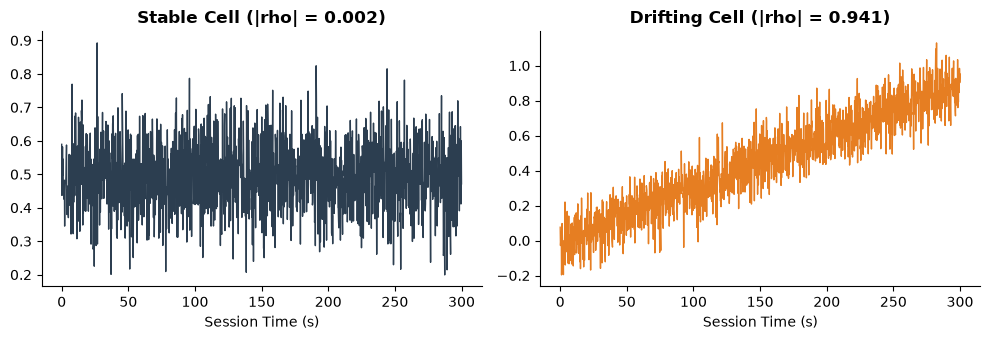

In [16]:
def generate_temporal_drift_exemplars():
    t = np.linspace(0, 300, 1500)
    trace_stable = 0.5 + 0.1 * np.random.randn(1500)
    trace_drifting = 0.003 * t + 0.1 * np.random.randn(1500)
    score_stable = compute_temporal_drift_score(t, trace_stable)
    score_drift = compute_temporal_drift_score(t, trace_drifting)
    return {"t": t, "trace_stable": trace_stable, "score_stable": score_stable, 
            "trace_drift": trace_drifting, "score_drift": score_drift}

td_ex = generate_temporal_drift_exemplars()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=100)
axes[0].plot(td_ex["t"], td_ex["trace_stable"], color='#2c3e50', lw=1)
axes[0].set_title(f"Stable Cell (|rho| = {td_ex['score_stable']:.3f})", fontweight="bold")
axes[1].plot(td_ex["t"], td_ex["trace_drift"], color='#e67e22', lw=1)
axes[1].set_title(f"Drifting Cell (|rho| = {td_ex['score_drift']:.3f})", fontweight="bold")
for ax in axes:
    ax.set_xlabel("Session Time (s)")
    ax.grid(False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Dual-Scale Oscillations & Slow Envelope Quantification
### Theory
To fully characterize multi-timescale temporal organization, the autocorrelogram is analyzed at two distinct frequency bands:
1. **Fast Scale (Carrier Frequency & Score)**: Extracted from autocorrelogram peaks within the $0.5\text{ s} - 30.0\text{ s}$ lag window. It yields the intrinsic oscillatory frequency $f_{\text{fast}} = 1 / T_{\text{fast}}$ and its prominence (Fast Score).
2. **Slow Scale (Envelope Frequency & Score)**: Extracted by computing the Hilbert upper envelope of the autocorrelogram and analyzing periodicity within the $30.0\text{ s} - 250.0\text{ s}$ window. This yields the slow modulation frequency $f_{\text{slow}} = 1 / T_{\text{slow}}$ and its modulation depth (Slow Score).

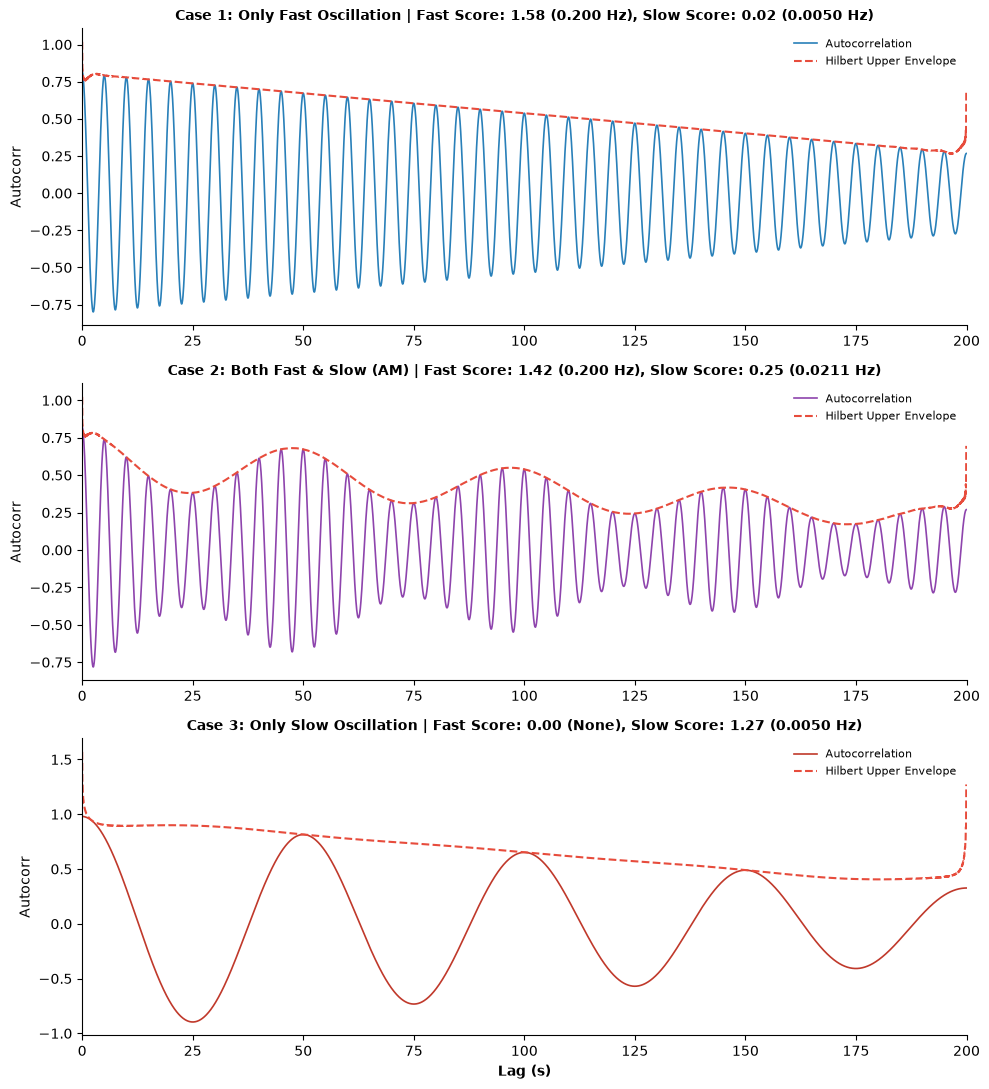

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.ndimage import gaussian_filter1d

def compute_dual_scale_metrics(trace: np.ndarray, fs: float = 20.0, max_lag_s: float = 200.0) -> dict:
    """
    Computes fast and slow oscillation scores and frequencies from the signal autocorrelogram and its envelope.
    """
    x = trace - np.mean(trace)
    var = np.var(trace)
    if var <= 1e-12:
        return {"fast_score": 0.0, "fast_freq": np.nan, "slow_score": 0.0, "slow_freq": np.nan, 
                "lags": np.array([]), "acorr": np.array([]), "envelope": np.array([])}

    # 1. Autocorrelogram computation
    autocorr = signal.correlate(x, x, mode="full")[len(trace) - 1:]
    autocorr = autocorr / (len(trace) * var)
    lags_s = np.arange(len(autocorr)) / fs
    smooth_acorr = gaussian_filter1d(autocorr, sigma=max(1, int(fs * 0.5)))
    
    max_idx = min(len(lags_s), int(max_lag_s * fs))
    sub_lags = lags_s[:max_idx]
    sub_acorr = smooth_acorr[:max_idx]

    # 2. Fast Oscillation Characterization (0.5s - 30.0s)
    fast_score, fast_freq = 0.0, np.nan
    fast_mask = (sub_lags >= 0.5) & (sub_lags <= 30.0)
    if np.any(fast_mask):
        peaks_f, props_f = signal.find_peaks(sub_acorr[fast_mask], prominence=0.005)
        if len(peaks_f) > 0:
            best_f = np.argmax(props_f["prominences"])
            t_fast = float(sub_lags[fast_mask][peaks_f[best_f]])
            fast_score = float(props_f["prominences"][best_f])
            if t_fast > 0:
                fast_freq = 1.0 / t_fast

    # 3. Slow Envelope Characterization (30.0s - 200.0s)
    analytic_acorr = signal.hilbert(sub_acorr)
    upper_envelope = np.abs(analytic_acorr)
    
    slow_score, slow_freq = 0.0, np.nan
    slow_mask = (sub_lags >= 30.0) & (sub_lags <= max_lag_s)
    if np.any(slow_mask):
        sub_l_slow = sub_lags[slow_mask]
        sub_env_slow = upper_envelope[slow_mask]
        peaks_s, props_s = signal.find_peaks(sub_env_slow, prominence=0.01)
        if len(peaks_s) > 0:
            best_s = np.argmax(props_s["prominences"])
            t_slow = float(sub_l_slow[peaks_s[best_s]])
            slow_score = float(props_s["prominences"][best_s])
            if t_slow > 0:
                slow_freq = 1.0 / t_slow
        else:
            # Fallback to max envelope point if distinct peaks are not prominent
            max_s_idx = np.argmax(sub_env_slow)
            t_slow = float(sub_l_slow[max_s_idx])
            slow_score = float(sub_env_slow[max_s_idx])
            if t_slow > 0:
                slow_freq = 1.0 / t_slow

    return {
        "fast_score": fast_score,
        "fast_freq": fast_freq,
        "slow_score": slow_score,
        "slow_freq": slow_freq,
        "lags": sub_lags,
        "acorr": sub_acorr,
        "envelope": upper_envelope
    }


# =============================================================================
# Simulation of 3 Cases and Plotting Suite
# =============================================================================
def run_dual_scale_3_examples():
    np.random.seed(42)
    fs = 20.0
    t_vec = np.linspace(0, 300, int(300 * fs))
    
    # Case 1: Only Fast Oscillation (Carrier frequency = 0.2 Hz, T = 5s, no modulation)
    sig_fast = np.sin(2 * np.pi * 0.2 * t_vec) + 0.1 * np.random.randn(len(t_vec))
    res_fast = compute_dual_scale_metrics(sig_fast, fs)
    
    # Case 2: Both Fast and Slow (Amplitude Modulated: 0.2 Hz carrier modulated by 0.02 Hz envelope)
    sig_both = np.sin(2 * np.pi * 0.2 * t_vec) * (1.0 + 0.8 * np.cos(2 * np.pi * 0.02 * t_vec)) + 0.1 * np.random.randn(len(t_vec))
    res_both = compute_dual_scale_metrics(sig_both, fs)
    
    # Case 3: Only Slow Oscillation / Modulation (Pure slow wave at 0.02 Hz, T = 50s)
    sig_slow = np.sin(2 * np.pi * 0.02 * t_vec) + 0.1 * np.random.randn(len(t_vec))
    res_slow = compute_dual_scale_metrics(sig_slow, fs)
    
    # Plotting 3 Examples
    fig, axes = plt.subplots(3, 1, figsize=(10, 11), dpi=100)
    
    cases = [
        ("Case 1: Only Fast Oscillation", res_fast, "#2980b9"),
        ("Case 2: Both Fast & Slow (AM)", res_both, "#8e44ad"),
        ("Case 3: Only Slow Oscillation", res_slow, "#c0392b")
    ]
    
    for idx, (title, res, color) in enumerate(cases):
        ax = axes[idx]
        ax.plot(res["lags"], res["acorr"], color=color, lw=1.2, label="Autocorrelation")
        ax.plot(res["lags"], res["envelope"], color="#e74c3c", lw=1.5, linestyle="--", label="Hilbert Upper Envelope")
        
        f_txt = f"{res['fast_freq']:.3f} Hz" if np.isfinite(res['fast_freq']) else "None"
        s_txt = f"{res['slow_freq']:.4f} Hz" if np.isfinite(res['slow_freq']) else "None"
        
        ax.set_title(f"{title} | Fast Score: {res['fast_score']:.2f} ({f_txt}), Slow Score: {res['slow_score']:.2f} ({s_txt})", fontweight="bold", fontsize=10)
        ax.set_xlim(0, 200)
        ax.set_ylabel("Autocorr")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
        ax.grid(False)
        ax.spines[["top", "right"]].set_visible(False)
        
    axes[-1].set_xlabel("Lag (s)", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()

run_dual_scale_3_examples()

## 6. Remapping Score (Only for High Placeness Cells)
### Theory
Measures place field instability or spatial shifts between the first half ($H_1$) and second half ($H_2$) of a recording session:
$$\text{Remapping Score} = 1.0 - \text{Pearson } r(\text{Tuning}_{H1}, \text{Tuning}_{H2})$$
A score near $0$ indicates a stable place field anchored in the same location across both halves, whereas higher scores indicate place field translation or reorganization.

In [30]:
def compute_remapping_score(pos: np.ndarray, trace: np.ndarray, n_bins: int = 50) -> tuple[float, np.ndarray, np.ndarray]:
    """
    Computes within-session remapping score by comparing spatial tuning curves across session halves.
    """
    half_pt = len(trace) // 2
    p_mi, p_ma = float(np.nanmin(pos)), float(np.nanmax(pos))
    
    def get_tune(p, tr):
        b_ed = np.linspace(p_mi, p_ma, n_bins + 1)
        b_id = np.clip(np.digitize(p, b_ed[1:-1]), 0, n_bins - 1)
        occ = np.bincount(b_id, minlength=n_bins).astype(float)
        act = np.bincount(b_id, weights=tr, minlength=n_bins).astype(float)
        tune = np.zeros(n_bins, dtype=float)
        val = occ > 0
        tune[val] = act[val] / occ[val]
        return gaussian_filter1d(tune, sigma=1.5, mode="nearest")

    tune_h1 = get_tune(pos[:half_pt], trace[:half_pt])
    tune_h2 = get_tune(pos[half_pt:], trace[half_pt:])
    
    if np.std(tune_h1) < 1e-12 or np.std(tune_h2) < 1e-12:
        return 1.0, tune_h1, tune_h2
    r, _ = stats.pearsonr(tune_h1, tune_h2)
    remap_score = float(np.clip(1.0 - r, 0.0, 2.0))
    return remap_score, tune_h1, tune_h2

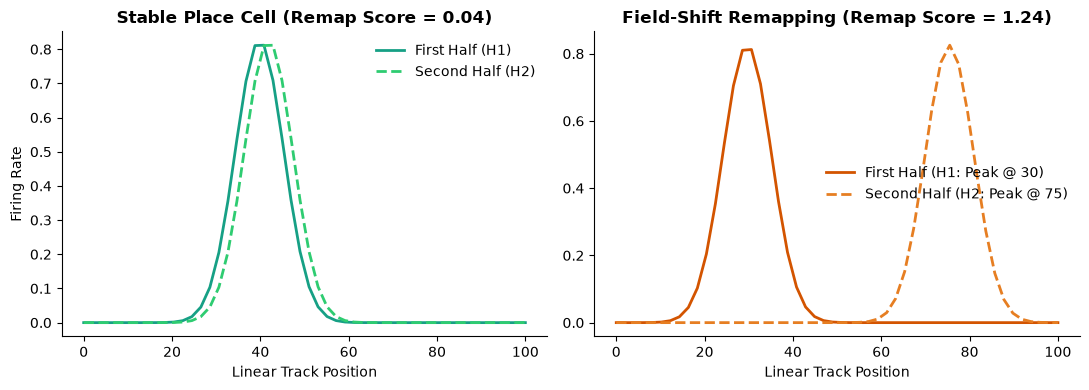

In [31]:
# Simulation & Plotting Example (Stable vs Field-Shift Remapping)
def run_remapping_simulation():
    n_pts = 4000
    pos = np.tile(np.linspace(0, 100, 500), 8)
    bin_x = np.linspace(0, 100, 50)
    half = n_pts // 2
    
    # 1. Stable Cell: Field stays at position 40 in both halves
    trace_stable = np.concatenate([
        np.exp(-((pos[:half] - 40.0)**2) / 40.0),
        np.exp(-((pos[half:] - 42.0)**2) / 40.0)
    ])
    score_stable, h1_s, h2_s = compute_remapping_score(pos, trace_stable)

    # 2. Field-Shift Remapping Cell: Field translates from position 30 to position 75
    trace_remap = np.concatenate([
        np.exp(-((pos[:half] - 30.0)**2) / 40.0),
        np.exp(-((pos[half:] - 75.0)**2) / 40.0)
    ])
    score_remap, h1_r, h2_r = compute_remapping_score(pos, trace_remap)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=100)
    
    axes[0].plot(bin_x, h1_s, color='#16a085', lw=2, label='First Half (H1)')
    axes[0].plot(bin_x, h2_s, color='#2ecc71', lw=2, linestyle='--', label='Second Half (H2)')
    axes[0].set_title(f"Stable Place Cell (Remap Score = {score_stable:.2f})", fontweight="bold")
    axes[0].set_xlabel("Linear Track Position")
    axes[0].set_ylabel("Firing Rate")
    axes[0].legend(frameon=False)
    
    axes[1].plot(bin_x, h1_r, color='#d35400', lw=2, label='First Half (H1: Peak @ 30)')
    axes[1].plot(bin_x, h2_r, color='#e67e22', lw=2, linestyle='--', label='Second Half (H2: Peak @ 75)')
    axes[1].set_title(f"Field-Shift Remapping (Remap Score = {score_remap:.2f})", fontweight="bold")
    axes[1].set_xlabel("Linear Track Position")
    axes[1].legend(frameon=False)
    
    for ax in axes:
        ax.grid(False)
        ax.spines[["top", "right"]].set_visible(False)
        
    plt.tight_layout()
    plt.show()

run_remapping_simulation()

## 8. Speedness Score
### Theory
Quantifies velocity modulation strength. While the speed score is standard in systems neuroscience literature (particularly for medial entorhinal cortex speed cells), here we compute it using the absolute Spearman rank correlation coefficient ($\rho_{\text{spearman}}$) between instantaneous running speed bins and neural activity tuning:
$$\text{Speedness Score} = |\rho_{\text{spearman}}(\text{Speed Bins}, \text{Activity Tuning})|$$

In [33]:
def compute_speedness_score(speed: np.ndarray, trace: np.ndarray, n_bins: int = 20) -> float:
    """
    Computes running speed modulation score via Spearman rank correlation across velocity bins.
    """
    s_min, s_max = float(np.nanmin(speed)), float(np.nanmax(speed))
    if s_max <= s_min or np.std(trace) < 1e-6:
        return 0.0
    bin_edges = np.linspace(s_min, s_max, n_bins + 1)
    bin_idx = np.clip(np.digitize(speed, bin_edges[1:-1]), 0, n_bins - 1)
    occupancy = np.bincount(bin_idx, minlength=n_bins).astype(float)
    activity = np.bincount(bin_idx, weights=trace, minlength=n_bins).astype(float)
    tuning = np.zeros(n_bins, dtype=float)
    valid = occupancy > 0
    tuning[valid] = activity[valid] / occupancy[valid]
    valid_t = np.isfinite(tuning)
    if np.sum(valid_t) < 5:
        return 0.0
    rho, _ = stats.spearmanr(np.arange(n_bins)[valid_t], tuning[valid_t])
    return float(abs(rho)) if np.isfinite(rho) else 0.0

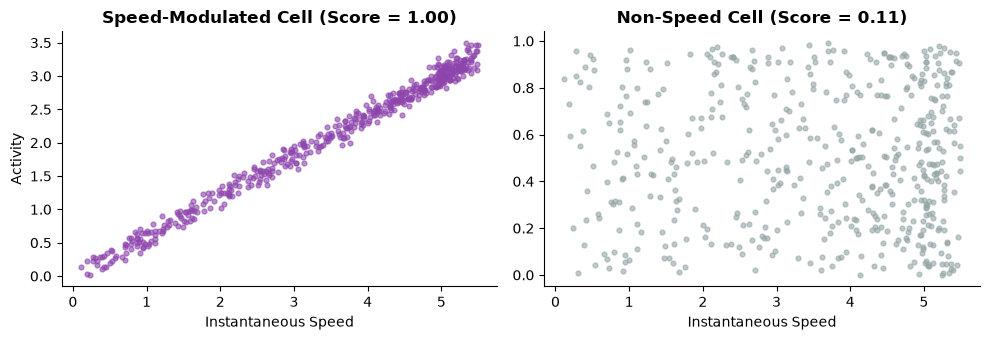

In [34]:
# Simulation & Plotting Example
def run_speedness_simulation():
    np.random.seed(42)
    n_pts = 3000
    speed = np.abs(5.0 * np.sin(np.linspace(0, 30, n_pts))) + 0.5 * np.random.rand(n_pts)
    
    # Speed-Modulated Cell (activity increases linearly with speed)
    trace_speed = 0.6 * speed + 0.1 * np.random.randn(n_pts)
    trace_speed = np.clip(trace_speed, 0, None)
    
    # Non-Speed Cell (flat response independent of speed)
    trace_normal = np.random.rand(n_pts)
    
    score_speed = compute_speedness_score(speed, trace_speed)
    score_normal = compute_speedness_score(speed, trace_normal)
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), dpi=100)
    axes[0].scatter(speed[:500], trace_speed[:500], color='#8e44ad', s=12, alpha=0.6)
    axes[0].set_title(f"Speed-Modulated Cell (Score = {score_speed:.2f})", fontweight="bold")
    axes[0].set_xlabel("Instantaneous Speed")
    axes[0].set_ylabel("Activity")
    
    axes[1].scatter(speed[:500], trace_normal[:500], color='#95a5a6', s=12, alpha=0.6)
    axes[1].set_title(f"Non-Speed Cell (Score = {score_normal:.2f})", fontweight="bold")
    axes[1].set_xlabel("Instantaneous Speed")
    
    for ax in axes:
        ax.grid(False)
        ax.spines[["top", "right"]].set_visible(False)
        
    plt.tight_layout()
    plt.show()

run_speedness_simulation()

## 9. Spatial Stability / Reliability Score (Trial-by-Trial Correlation)
### Theory
While session-level remapping compares coarse halves of a recording, **Spatial Stability** measures the fine-grained reproducibility of a place cell's firing across individual trials (traversals) on the linear track. It is computed as the mean pairwise Pearson correlation coefficient ($r$) 
between the spatial tuning curve of each individual trial and the mean tuning curve of all other trials:
$$\text{Stability} = \frac{1}{N} \sum_{i=1}^{N} \text{Pearson } r(\text{Tuning}_{\text{trial } i}, \text{Tuning}_{\text{mean}(-i)})$$
Values closer to $1.0$ indicate highly reliable and stable place fields, whereas values near $0$ or negative indicate erratic or unstable firing across laps.


In [37]:
def compute_spatial_stability(pos: np.ndarray, trace: np.ndarray, trial_ids: np.ndarray, n_bins: int = 50) -> float:
    """
    Computes trial-by-trial spatial stability as the mean Pearson correlation of 
    each individual trial's tuning curve with the leave-one-out mean tuning curve.
    """
    unique_trials = np.unique(trial_ids)
    valid_trials = [t for t in unique_trials if t >= 0]
    if len(valid_trials) < 3:
        return np.nan
        
    p_mi, p_ma = float(np.nanmin(pos)), float(np.nanmax(pos))
    b_ed = np.linspace(p_mi, p_ma, n_bins + 1)
    
    trial_tunes = {}
    for t_id in valid_trials:
        mask = (trial_ids == t_id) & np.isfinite(pos) & np.isfinite(trace)
        if np.sum(mask) < 5:
            continue
        p_t, tr_t = pos[mask], trace[mask]
        b_id = np.clip(np.digitize(p_t, b_ed[1:-1]), 0, n_bins - 1)
        occ = np.bincount(b_id, minlength=n_bins).astype(float)
        act = np.bincount(b_id, weights=tr_t, minlength=n_bins).astype(float)
        tune = np.zeros(n_bins, dtype=float)
        val = occ > 0
        tune[val] = act[val] / occ[val]
        trial_tunes[t_id] = gaussian_filter1d(tune, sigma=1.5, mode="nearest")
        
    valid_keys = list(trial_tunes.keys())
    if len(valid_keys) < 3:
        return np.nan
        
    corrs = []
    for t_id in valid_keys:
        t_curr = trial_tunes[t_id]
        others = [trial_tunes[k] for k in valid_keys if k != t_id]
        t_mean = np.mean(others, axis=0)
        
        valid_bins = np.isfinite(t_curr) & np.isfinite(t_mean) & (np.std(t_curr) > 1e-6) & (np.std(t_mean) > 1e-6)
        if np.sum(valid_bins) > 5:
            r_val, _ = stats.pearsonr(t_curr[valid_bins], t_mean[valid_bins])
            if np.isfinite(r_val):
                corrs.append(r_val)
                
    return float(np.mean(corrs)) if len(corrs) > 0 else 0.0

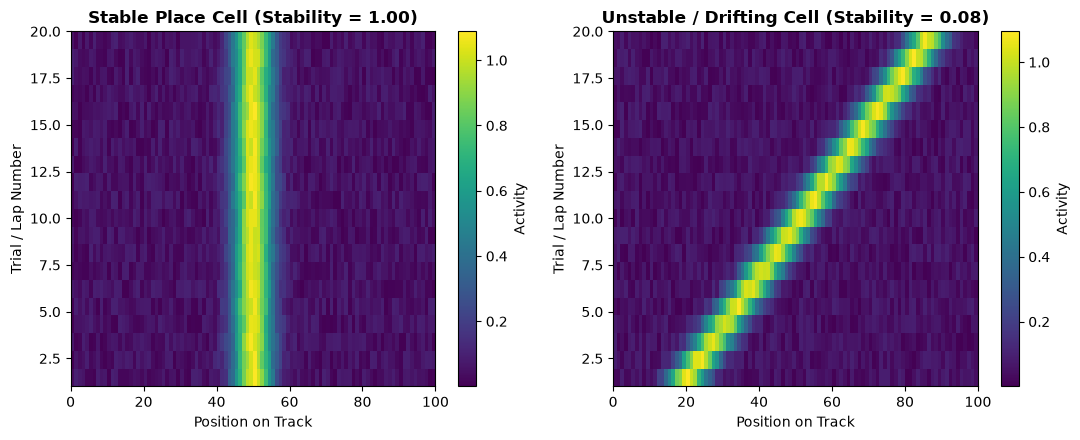

In [41]:
def run_spatial_stability_simulation():
    np.random.seed(42)
    n_trials = 20
    pts_per_trial = 100
    
    pos = np.tile(np.linspace(0, 100, pts_per_trial), n_trials)
    trial_ids = np.repeat(np.arange(n_trials), pts_per_trial)
    
    # 1. Stable Place Cell: Firing field remains locked at position 50 across all trials
    stable_list = []
    for i in range(n_trials):
        sub_pos = np.linspace(0, 100, pts_per_trial)
        trial_trace = np.exp(-((sub_pos - 50.0)**2) / 30.0) + 0.1 * np.random.rand(pts_per_trial)
        stable_list.append(trial_trace)
    trace_stable = np.concatenate(stable_list)
    
    # 2. Unstable / Drifting Cell: Firing field progressively drifts across trials
    unstable_list = []
    for i in range(n_trials):
        sub_pos = np.linspace(0, 100, pts_per_trial)
        peak_pos = 20.0 + 3.5 * i  # Field moves linearly across laps
        trial_trace = np.exp(-((sub_pos - peak_pos)**2) / 30.0) + 0.1 * np.random.rand(pts_per_trial)
        unstable_list.append(trial_trace)
    trace_unstable = np.concatenate(unstable_list)
    
    score_stable = compute_spatial_stability(pos, trace_stable, trial_ids)
    score_unstable = compute_spatial_stability(pos, trace_unstable, trial_ids)
    
    # Reshape traces into (n_trials, pts_per_trial) matrices for heat map plotting
    mat_stable = trace_stable.reshape(n_trials, pts_per_trial)
    mat_unstable = trace_unstable.reshape(n_trials, pts_per_trial)
    
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=100)
    
    im0 = axes[0].imshow(mat_stable, aspect='auto', origin='lower', extent=[0, 100, 1, n_trials], cmap='viridis')
    axes[0].set_title(f"Stable Place Cell (Stability = {score_stable:.2f})", fontweight="bold")
    axes[0].set_xlabel("Position on Track")
    axes[0].set_ylabel("Trial / Lap Number")
    fig.colorbar(im0, ax=axes[0], label="Activity")
    
    im1 = axes[1].imshow(mat_unstable, aspect='auto', origin='lower', extent=[0, 100, 1, n_trials], cmap='viridis')
    axes[1].set_title(f"Unstable / Drifting Cell (Stability = {score_unstable:.2f})", fontweight="bold")
    axes[1].set_xlabel("Position on Track")
    axes[1].set_ylabel("Trial / Lap Number")
    fig.colorbar(im1, ax=axes[1], label="Activity")
    
    plt.tight_layout()
    plt.show()

run_spatial_stability_simulation()

## 10. Normalized Place Field Size Variability (Coefficient of Variation)
### Theory
To quantify trial-by-trial place field size instability or expansion independently of a cell's baseline field width, we use the **Coefficient of Variation of the Place Field Size** ($\text{CV}_{\text{size}}$):
$$\text{CV}_{\text{size}} = \frac{\sigma(\text{Sizes}_{\text{trials}})}{\mu(\text{Sizes}_{\text{trials}})}$$
- **Low CV ($\approx 0.05 - 0.15$)**: Stable field width across all laps.
- **High CV ($> 0.30$)**: Progressive expansion, contraction, or erratic size modulation across trials.

Constant Cell   -> Mean Size: 12.0 cm | Std: 0.00 cm | Normalized CV: 0.000
Expanding Cell  -> Mean Size: 83.4 cm | Std: 24.54 cm | Normalized CV: 0.294


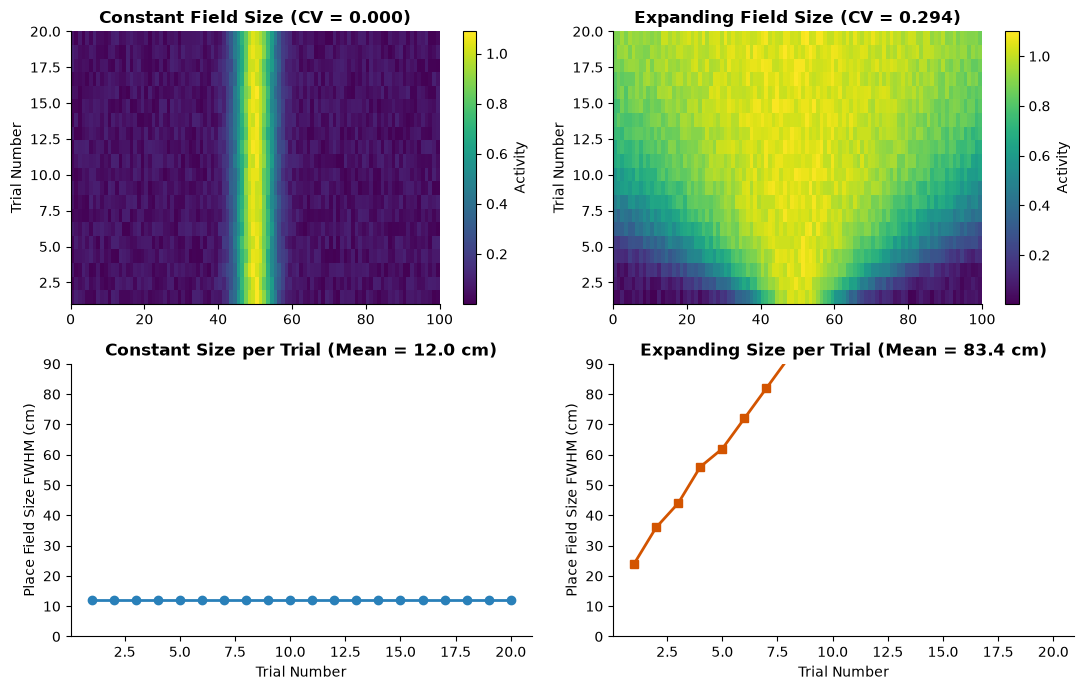

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

def compute_normalized_field_size_variability(pos: np.ndarray, trace: np.ndarray, trial_ids: np.ndarray, n_bins: int = 50) -> tuple[float, float, float, np.ndarray]:
    """
    Computes the normalized place field size variability (Coefficient of Variation: std / mean).
    Returns (cv_score, mean_size, std_size, trial_sizes_array).
    """
    unique_trials = np.unique(trial_ids)
    valid_trials = [t for t in unique_trials if t >= 0]
    p_mi, p_ma = float(np.nanmin(pos)), float(np.nanmax(pos))
    bin_edges = np.linspace(p_mi, p_ma, n_bins + 1)
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
    bin_resolution = bin_centers[1] - bin_centers[0]
    
    trial_sizes = []
    for t_id in valid_trials:
        mask = (trial_ids == t_id) & np.isfinite(pos) & np.isfinite(trace)
        if np.sum(mask) < 5:
            trial_sizes.append(np.nan)
            continue
        p_t, tr_t = pos[mask], trace[mask]
        b_id = np.clip(np.digitize(p_t, bin_edges[1:-1]), 0, n_bins - 1)
        occ = np.bincount(b_id, minlength=n_bins).astype(float)
        act = np.bincount(b_id, weights=tr_t, minlength=n_bins).astype(float)
        tune = np.zeros(n_bins, dtype=float)
        val = occ > 0
        tune[val] = act[val] / occ[val]
        tune = gaussian_filter1d(tune, sigma=1.5, mode="nearest")
        
        if np.max(tune) > 1e-6:
            half_max = 0.5 * np.max(tune)
            above = tune >= half_max
            if np.any(above):
                idx = np.where(above)[0]
                size = (idx[-1] - idx[0] + 1) * bin_resolution
                trial_sizes.append(size)
            else:
                trial_sizes.append(0.0)
        else:
            trial_sizes.append(0.0)
            
    trial_sizes = np.array(trial_sizes)
    valid_mask = np.isfinite(trial_sizes) & (trial_sizes > 0)
    filtered_sizes = trial_sizes[valid_mask]
    
    if len(filtered_sizes) < 3 or np.mean(filtered_sizes) <= 1e-12:
        return np.nan, np.nan, np.nan, trial_sizes
        
    mean_sz = float(np.mean(filtered_sizes))
    std_sz = float(np.std(filtered_sizes))
    cv_score = std_sz / mean_sz
    return cv_score, mean_sz, std_sz, trial_sizes


def run_field_size_quantification_and_plotting():
    np.random.seed(42)
    n_trials = 20
    pts_per_trial = 100
    pos = np.tile(np.linspace(0, 100, pts_per_trial), n_trials)
    trial_ids = np.repeat(np.arange(n_trials), pts_per_trial)
    
    # 1. Constant Field Size Cell simulation
    const_list = []
    for _ in range(n_trials):
        sub_p = np.linspace(0, 100, pts_per_trial)
        const_list.append(np.exp(-((sub_p - 50.0)**2) / 30.0) + 0.1 * np.random.rand(pts_per_trial))
    trace_const = np.concatenate(const_list)
    
    # 2. Expanding Field Size Cell simulation (width grows linearly across trials)
    expanding_list = []
    for i in range(n_trials):
        sub_p = np.linspace(0, 100, pts_per_trial)
        sigma_val = 10.0 + 4.0 * i  
        expanding_list.append(np.exp(-((sub_p - 50.0)**2) / (2 * sigma_val**2)) + 0.1 * np.random.rand(pts_per_trial))
    trace_expanding = np.concatenate(expanding_list)
    
    # Compute scores
    cv_c, mean_c, std_c, sizes_c = compute_normalized_field_size_variability(pos, trace_const, trial_ids, 50)
    cv_e, mean_e, std_e, sizes_e = compute_normalized_field_size_variability(pos, trace_expanding, trial_ids, 50)
    
    print(f"Constant Cell   -> Mean Size: {mean_c:.1f} cm | Std: {std_c:.2f} cm | Normalized CV: {cv_c:.3f}")
    print(f"Expanding Cell  -> Mean Size: {mean_e:.1f} cm | Std: {std_e:.2f} cm | Normalized CV: {cv_e:.3f}")
    
    # Plotting Suite
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), dpi=100)
    
    # Row 0: Trial-by-Trial Activity Heat Maps
    im0 = axes[0, 0].imshow(trace_const.reshape(n_trials, pts_per_trial), aspect='auto', origin='lower', extent=[0, 100, 1, n_trials], cmap='viridis')
    axes[0, 0].set_title(f"Constant Field Size (CV = {cv_c:.3f})", fontweight="bold")
    axes[0, 0].set_ylabel("Trial Number")
    fig.colorbar(im0, ax=axes[0, 0], label="Activity")
    
    im1 = axes[0, 1].imshow(trace_expanding.reshape(n_trials, pts_per_trial), aspect='auto', origin='lower', extent=[0, 100, 1, n_trials], cmap='viridis')
    axes[0, 1].set_title(f"Expanding Field Size (CV = {cv_e:.3f})", fontweight="bold")
    axes[0, 1].set_ylabel("Trial Number")
    fig.colorbar(im1, ax=axes[0, 1], label="Activity")
    
    # Row 1: Trial-by-Trial FWHM Size Evolution Curves
    trials_axis = np.arange(1, n_trials + 1)
    axes[1, 0].plot(trials_axis, sizes_c, marker='o', color='#2980b9', lw=2)
    axes[1, 0].set_title(f"Constant Size per Trial (Mean = {mean_c:.1f} cm)", fontweight="bold")
    axes[1, 0].set_xlabel("Trial Number")
    axes[1, 0].set_ylabel("Place Field Size FWHM (cm)")
    axes[1, 0].set_ylim(0, 90)
    
    axes[1, 1].plot(trials_axis, sizes_e, marker='s', color='#d35400', lw=2)
    axes[1, 1].set_title(f"Expanding Size per Trial (Mean = {mean_e:.1f} cm)", fontweight="bold")
    axes[1, 1].set_xlabel("Trial Number")
    axes[1, 1].set_ylabel("Place Field Size FWHM (cm)")
    axes[1, 1].set_ylim(0, 90)
    
    for row in axes:
        for ax in row:
            ax.grid(False)
            ax.spines[["top", "right"]].set_visible(False)
            
    plt.tight_layout()
    plt.show()

run_field_size_quantification_and_plotting()